# Check-in 2: Will There Be a Divvy Bike? (Data in hand)
**Team:** Jonathan Afari Takyi, Nick, Daniel

**Data:** Divvy trip history, September 2026 (`202609-divvy-tripdata.zip`), published by Divvy (Lyft) for the City of Chicago.
Source index: https://divvy-tripdata.s3.amazonaws.com/index.html

**How to run:** In Colab, choose *Runtime > Run all*. The first cell downloads the file from Divvy's public bucket (about 30 MB), so nothing needs uploading.

**Sections:** 1. Load the data · 2. What's in it · 3. What's wrong with it · 4. Three questions · 5. One surprise

## 1. Load the data

In [1]:
# Standard data tools. pandas = tables, numpy = math, matplotlib = charts.
import os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)

# Chart style shared by every figure, so all charts read as one set.
# The two series colors (blue, orange) were checked for colorblind separation.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10,
})

In [2]:
# Download the September 2026 file straight from Divvy unless a local copy exists.
# Why: anyone on the team (or the professor) can rerun this with no setup.
URL = "https://divvy-tripdata.s3.amazonaws.com/202609-divvy-tripdata.zip"
CSV = os.environ.get("DIVVY_CSV", "202609-divvy-tripdata.csv")

if not os.path.exists(CSV):
    raw = urllib.request.urlopen(URL).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        name = [n for n in z.namelist() if n.endswith(".csv") and not n.startswith("__MACOSX")][0]
        z.extract(name)
        CSV = name

# Parse the two time columns as real timestamps so we can do time math on them.
df = pd.read_csv(CSV, parse_dates=["started_at", "ended_at"])
print("Loaded", CSV)

Loaded /home/claude/data/202609-divvy-tripdata.csv


## 2. What's in it

In [3]:
# Size: rows x columns.
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print()
print(df.dtypes.to_string())

Rows: 770,562   Columns: 13

ride_id                          str
rideable_type                    str
started_at            datetime64[us]
ended_at              datetime64[us]
start_station_name               str
start_station_id                 str
end_station_name                 str
end_station_id                   str
start_lat                    float64
start_lng                    float64
end_lat                      float64
end_lng                      float64
member_casual                    str


In [4]:
# Date range. Trips are filed by the month they END, so a few start on Aug 31.
print("First trip start:", df.started_at.min())
print("Last trip start: ", df.started_at.max())
print("Trips starting before Sep 1:", (df.started_at < "2026-09-01").sum())

First trip start: 2026-08-31 00:53:20.571000
Last trip start:  2026-09-30 23:59:38.090000
Trips starting before Sep 1: 51


In [5]:
# What one row means: one anonymized trip on one bike, from start to end.
df.head(3).T

,0,1,2
ride_id,B3C076B2D6BAC911,468834E54297FB3F,276E6265CF1F0238
rideable_type,electric_bike,electric_bike,electric_bike
started_at,2026-09-01 19:28:37.087000,2026-09-24 20:38:01.486000,2026-09-24 20:01:27.138000
ended_at,2026-09-01 19:33:03.047000,2026-09-24 20:44:54.382000,2026-09-24 20:08:32.366000
start_station_name,NaN,NaN,NaN
start_station_id,NaN,NaN,NaN
end_station_name,NaN,NaN,NaN
end_station_id,NaN,NaN,NaN
start_lat,41.87,41.91,41.9
start_lng,-87.67,-87.7,-87.71


In [6]:
# The two category columns: bike type and rider type.
print(df.rideable_type.value_counts().to_string(), "\n")
print(df.member_casual.value_counts().to_string())

rideable_type
electric_bike    580638
classic_bike     189924 

member_casual
member    476442
casual    294120


## 3. What's wrong with it

In [7]:
# Trip length in minutes. We use it to find impossible or suspicious trips.
df["minutes"] = (df.ended_at - df.started_at).dt.total_seconds() / 60

# E-bikes parked away from a station have no station name, and their coordinates
# are rounded to 2 decimals (about a 1 km grid), so their location is approximate.
no_station = df.start_station_name.isna()
rounded = (df.start_lat.round(2) == df.start_lat) & (df.start_lng.round(2) == df.start_lng)

issues = pd.DataFrame([
    ("Missing start station (name + id)", df.start_station_name.isna().sum()),
    ("Missing end station (name + id)", df.end_station_name.isna().sum()),
    ("Missing end coordinates", df.end_lat.isna().sum()),
    ("Start coordinates rounded to ~1 km", rounded.sum()),
    ("Trips under 1 minute", (df.minutes < 1).sum()),
    ("Trips over 24 hours", (df.minutes > 1440).sum()),
    ("Trips starting Aug 31 (outside the month)", (df.started_at < "2026-09-01").sum()),
    ("Duplicate ride_id", df.ride_id.duplicated().sum()),
], columns=["Issue", "Rows"])
issues["% of rows"] = (issues.Rows / len(df) * 100).round(2)
issues

,Issue,Rows,% of rows
0,Missing start station (name + id),160341,20.81
1,Missing end station (name + id),170033,22.07
2,Missing end coordinates,644,0.08
3,Start coordinates rounded to ~1 km,160341,20.81
4,Trips under 1 minute,18610,2.42
5,Trips over 24 hours,633,0.08
6,Trips starting Aug 31 (outside the month),51,0.01
7,Duplicate ride_id,0,0.00


In [8]:
# Is missing-station data random? No: it is almost all e-bikes.
# Classic bikes must be docked, so they always have a start station.
print("Share of trips with no start station, by bike type:")
print(df.groupby("rideable_type").start_station_name.apply(lambda s: s.isna().mean()).round(3).to_string())
print("\nRounded coordinates happen exactly when the station is missing:",
      (rounded == no_station).all())

Share of trips with no start station, by bike type:
rideable_type
classic_bike     0.000
electric_bike    0.276

Rounded coordinates happen exactly when the station is missing: True


In [9]:
# The trips with no end location: almost all are classic bikes stopped at ~25 hours.
# This looks like a system cap on bikes never returned (lost or stolen), not real rides.
no_end = df[df.end_lat.isna()]
print(no_end.rideable_type.value_counts().to_string())
print("\nMedian length of these trips (hours):", round(no_end.minutes.median() / 60, 1))
print("Of the", (df.minutes > 1440).sum(), "trips over 24h,", ((df.minutes > 1440) & df.end_lat.isna()).sum(), "also have no end location")

rideable_type
classic_bike    644

Median length of these trips (hours): 25.0
Of the 633 trips over 24h, 612 also have no end location


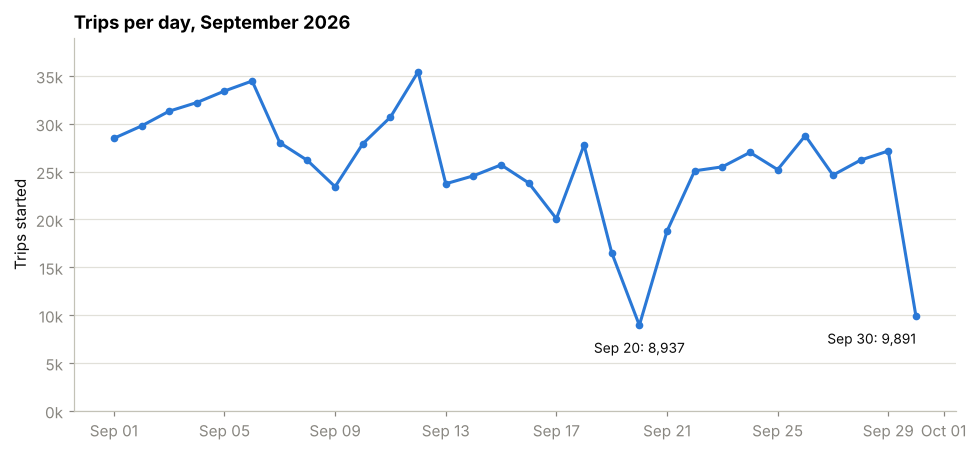

started_at
2026-09-20     8937
2026-09-30     9891
2026-09-19    16529


In [10]:
# Gaps: trips per day. Two days fall far below the rest.
daily = df[df.started_at >= "2026-09-01"].groupby(df.started_at.dt.date).size()
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color=BLUE, lw=2, marker="o", ms=4)
for d in ["2026-09-20", "2026-09-30"]:
    d = pd.Timestamp(d).date()
    ax.annotate(f"{d:%b %d}: {daily[d]:,}", (d, daily[d]), xytext=(0, -18),
                textcoords="offset points", ha="right" if d.day == 30 else "center", color=INK, fontsize=9)
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title("Trips per day, September 2026")
ax.set_ylabel("Trips started")
ax.set_ylim(0, daily.max() * 1.1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
plt.tight_layout(); plt.show()
print(daily.sort_values().head(3).to_string())

**Reading the dips.** Sept 19 and 20 fell under Flood Watches for Chicago in FOX 32's forecasts (Sept 19 and 20, 2026), and Sept 19's evening drop lines up with the forecast's 7 PM second round of rain. We have not yet matched these days against measured rainfall. Sept 30's midday dip is unexplained so far. Next step: join NOAA hourly weather before training any model, so the model does not learn "Sunday = empty" from one rainy Sunday.

## 4. Three questions

We focus on the stations closest to Loyola's Lake Shore Campus (1032 W Sheridan Rd, 41.99922, -87.65796 per latlong.net), within 1.2 km, about a 15-minute walk.

In [11]:
# Station locations: take the median coordinates of CLASSIC bike trips at each station.
# Why classic only: their coordinates are exact, while dockless e-bike points are rounded.
LSC_LAT, LSC_LNG, RADIUS_KM = 41.99922, -87.65796, 1.2

classic = df[df.rideable_type == "classic_bike"]
stations = classic.groupby("start_station_name").agg(lat=("start_lat", "median"), lng=("start_lng", "median"))

# Distance in km with a flat-earth approximation (accurate to meters at this scale).
stations["km"] = np.hypot((stations.lat - LSC_LAT) * 111.0,
                          (stations.lng - LSC_LNG) * 111.0 * np.cos(np.radians(LSC_LAT)))
near = stations[stations.km <= RADIUS_KM].sort_values("km")
NEAR = set(near.index)
near.round(4)

,lat,lng,km
start_station_name,,,
Winthrop Ave & Sheridan Rd,41.9981,-87.6588,0.1406
Sheridan Rd & Arthur Ave,42.0005,-87.6606,0.2562
Broadway & Granville Ave,41.9948,-87.6603,0.5289
Glenwood Ave & Devon Ave,41.9979,-87.6655,0.6347
Sheridan Rd & Columbia Ave,42.0046,-87.6614,0.6597
Broadway & Thorndale Ave,41.9897,-87.6601,1.0673
Clark St & Schreiber Ave,41.9992,-87.6712,1.0962
Granville Ave & Clark St,41.9944,-87.6698,1.1158
Glenwood Ave & Morse Ave,42.0080,-87.6655,1.1536


### Q1. Which stations near Loyola get the most use, and how much of it is at rush hour?

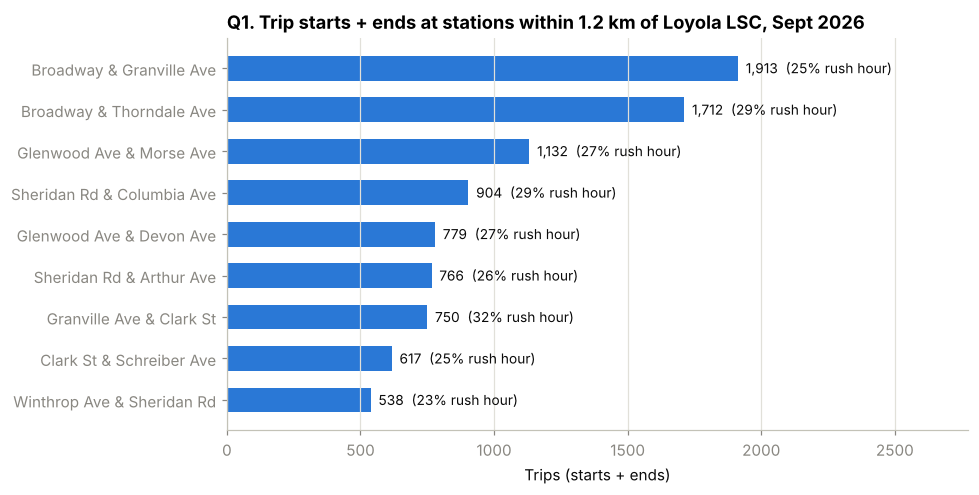

,total,rush,rush_share_%,km
station,,,,
Broadway & Granville Ave,1913,470,24.6,0.53
Broadway & Thorndale Ave,1712,490,28.6,1.07
Glenwood Ave & Morse Ave,1132,309,27.3,1.15
Sheridan Rd & Columbia Ave,904,261,28.9,0.66
Glenwood Ave & Devon Ave,779,210,27.0,0.63
Sheridan Rd & Arthur Ave,766,201,26.2,0.26
Granville Ave & Clark St,750,236,31.5,1.12
Clark St & Schreiber Ave,617,152,24.6,1.10
Winthrop Ave & Sheridan Rd,538,122,22.7,0.14


In [12]:
# Count every trip that starts OR ends at each nearby station (both use a bike or a dock).
# Rush hour = weekdays 7-10 AM and 4-7 PM, the windows named in Check-in 1.
def is_rush(ts):
    return (ts.dt.dayofweek < 5) & (ts.dt.hour.isin([7, 8, 9, 16, 17, 18]))

starts = df[df.start_station_name.isin(NEAR)].assign(rush=lambda x: is_rush(x.started_at))
ends = df[df.end_station_name.isin(NEAR)].assign(rush=lambda x: is_rush(x.ended_at))
use = pd.concat([
    starts.rename(columns={"start_station_name": "station"})[["station", "rush"]],
    ends.rename(columns={"end_station_name": "station"})[["station", "rush"]],
])
q1 = use.groupby("station").agg(total=("rush", "size"), rush=("rush", "sum"))
q1["rush_share_%"] = (q1.rush / q1.total * 100).round(1)
q1 = q1.join(near.km.round(2)).sort_values("total")

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(q1.index, q1.total, color=BLUE, height=0.6)
for i, (t, s) in enumerate(zip(q1.total, q1["rush_share_%"])):
    ax.text(t, i, f"  {t:,}  ({s:.0f}% rush hour)", va="center", fontsize=9, color=INK)
ax.set_title("Q1. Trip starts + ends at stations within 1.2 km of Loyola LSC, Sept 2026")
ax.set_xlabel("Trips (starts + ends)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True, color=GRID)
ax.set_xlim(0, q1.total.max() * 1.45)
plt.tight_layout(); plt.show()
q1.sort_values("total", ascending=False)

### Q2. At what hours do the Loyola-area stations lose bikes faster than they gain them?

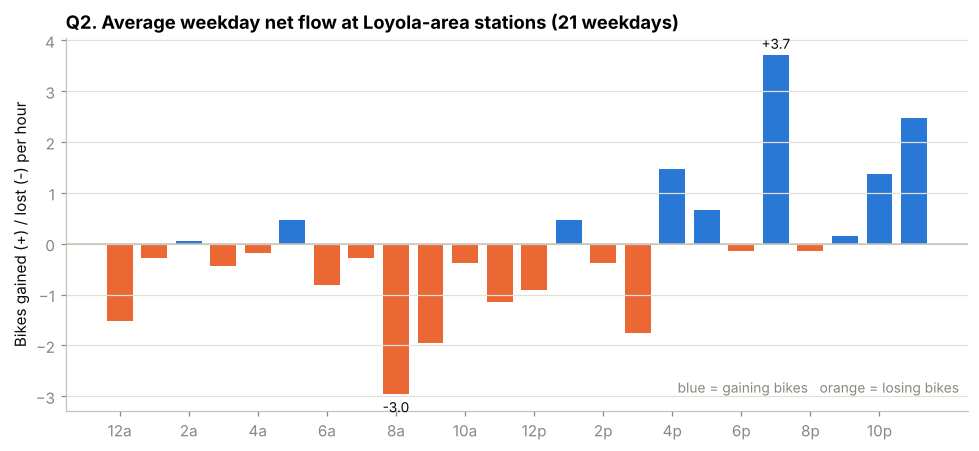

Biggest average loss: 8 :00 -> -3.0 bikes/hour
Biggest average gain: 19 :00 -> 3.7 bikes/hour


In [13]:
# Net flow per hour = bikes arriving minus bikes leaving, summed over the nearby stations.
# Negative = the stations are draining (riders at risk of finding them empty).
# Weekdays only, Labor Day (Sept 7) excluded, averaged per weekday.
wk = lambda ts: (ts.dt.dayofweek < 5) & (ts.dt.date != pd.Timestamp("2026-09-07").date()) & (ts >= "2026-09-01")
dep = starts[wk(starts.started_at)].groupby(starts.started_at.dt.hour).size()
arr = ends[wk(ends.ended_at)].groupby(ends.ended_at.dt.hour).size()
n_days = df.loc[wk(df.started_at), "started_at"].dt.date.nunique()
net = (arr.reindex(range(24), fill_value=0) - dep.reindex(range(24), fill_value=0)) / n_days

fig, ax = plt.subplots()
ax.bar(net.index, net.values, color=np.where(net >= 0, BLUE, ORANGE), width=0.75)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xticks(range(0, 24, 2), [f"{h%12 or 12}{'a' if h < 12 else 'p'}" for h in range(0, 24, 2)])
ax.set_title(f"Q2. Average weekday net flow at Loyola-area stations ({n_days} weekdays)")
ax.set_ylabel("Bikes gained (+) / lost (-) per hour")
ax.text(0.99, 0.04, "blue = gaining bikes   orange = losing bikes", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=9, color=MUTED)
for h in [net.idxmin(), net.idxmax()]:
    ax.annotate(f"{net[h]:+.1f}", (h, net[h]), xytext=(0, -12 if net[h] < 0 else 4),
                textcoords="offset points", ha="center", fontsize=9, color=INK)
plt.tight_layout(); plt.show()
print("Biggest average loss:", net.idxmin(), ":00 ->", round(net.min(), 1), "bikes/hour")
print("Biggest average gain:", net.idxmax(), ":00 ->", round(net.max(), 1), "bikes/hour")

### Q3. Do members and casual riders use Divvy at different times? (systemwide, weekdays)

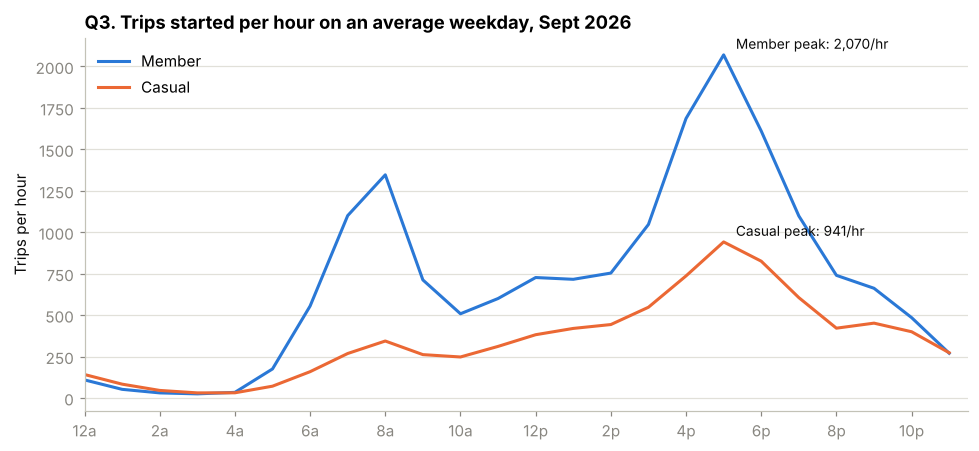

Peak hour, members: 17 :00   casual: 17 :00
Member share of weekday 8 AM trips: 79.7 %


In [14]:
# Members (annual pass) vs casual riders, trips started per hour on an average weekday.
# Why it matters: members are the commuters our app targets, so their peaks set the alert times.
wd = df[wk(df.started_at)]
q3 = wd.groupby([wd.started_at.dt.hour, "member_casual"]).size().unstack() / n_days

fig, ax = plt.subplots()
for col, color in [("member", BLUE), ("casual", ORANGE)]:
    ax.plot(q3.index, q3[col], color=color, lw=2, label=col.title())
    pk = q3[col].idxmax()
    ax.annotate(f"{col.title()} peak: {q3.loc[pk, col]:,.0f}/hr", (pk, q3.loc[pk, col]),
                xytext=(8, 4), textcoords="offset points", fontsize=9, color=INK)
ax.set_xticks(range(0, 24, 2), [f"{h%12 or 12}{'a' if h < 12 else 'p'}" for h in range(0, 24, 2)])
ax.set_xlim(0, 23.5)
ax.set_title("Q3. Trips started per hour on an average weekday, Sept 2026")
ax.set_ylabel("Trips per hour")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
peaks = q3.idxmax()
print("Peak hour, members:", peaks["member"], ":00   casual:", peaks["casual"], ":00")
print("Member share of weekday 8 AM trips:", round(q3.loc[8, "member"] / q3.loc[8].sum() * 100, 1), "%")

## 5. One surprise: a large share of trips never touch a station

In [15]:
# A station-based app only "sees" docked trips. How many trips does it miss?
ebike_share = (df.rideable_type == "electric_bike").mean()
ebike_dockless = df.loc[df.rideable_type == "electric_bike", "start_station_name"].isna().mean()
any_dockless = no_station.mean()
print(f"E-bikes are {ebike_share:.1%} of all trips.")
print(f"{ebike_dockless:.1%} of e-bike trips start with no station.")
print(f"So {any_dockless:.1%} of ALL trips start somewhere a station-based app cannot see.")

# Near Loyola: dockless starts fall on the rounded grid, so count the grid cells
# around campus (lat 41.99-42.01, lng -87.67 to -87.65). This is approximate (~1 km cells).
box = df.start_lat.between(41.985, 42.015) & df.start_lng.between(-87.675, -87.645)
local = df[box]
print(f"\nAround Loyola (approx.): {local.start_station_name.isna().mean():.1%} of {len(local):,} trip starts had no station.")

E-bikes are 75.4% of all trips.
27.6% of e-bike trips start with no station.
So 20.8% of ALL trips start somewhere a station-based app cannot see.

Around Loyola (approx.): 26.2% of 9,768 trip starts had no station.


**Why it's a surprise and why it matters.** We expected the problem to be "the station is empty." But a large share of riders skip stations entirely by grabbing a nearby e-bike. That changes the app. "Is there a bike?" should cover nearby dockless e-bikes, which the live GBFS feed (`free_bike_status`) lists, not only docks.

## Summary for Check-in 2
| Item | Answer |
|---|---|
| Size | see Section 2 output (770,562 rows × 13 columns in the Sept 2026 file) |
| One row | one anonymized bike trip, start to end |
| Biggest data problems | missing stations (all e-bikes), rounded coordinates, ~25-hour "trips" with no end, low-ridership days |
| Next | join weather, start saving the live station feed on a schedule, add Aug and Oct files |